# CMX E0–E3: All Research Plots
Run the next cell to generate 15 high-resolution PNG plots and CSV tables. The output folder is `~/Downloads/CMX_Research_Plots`.

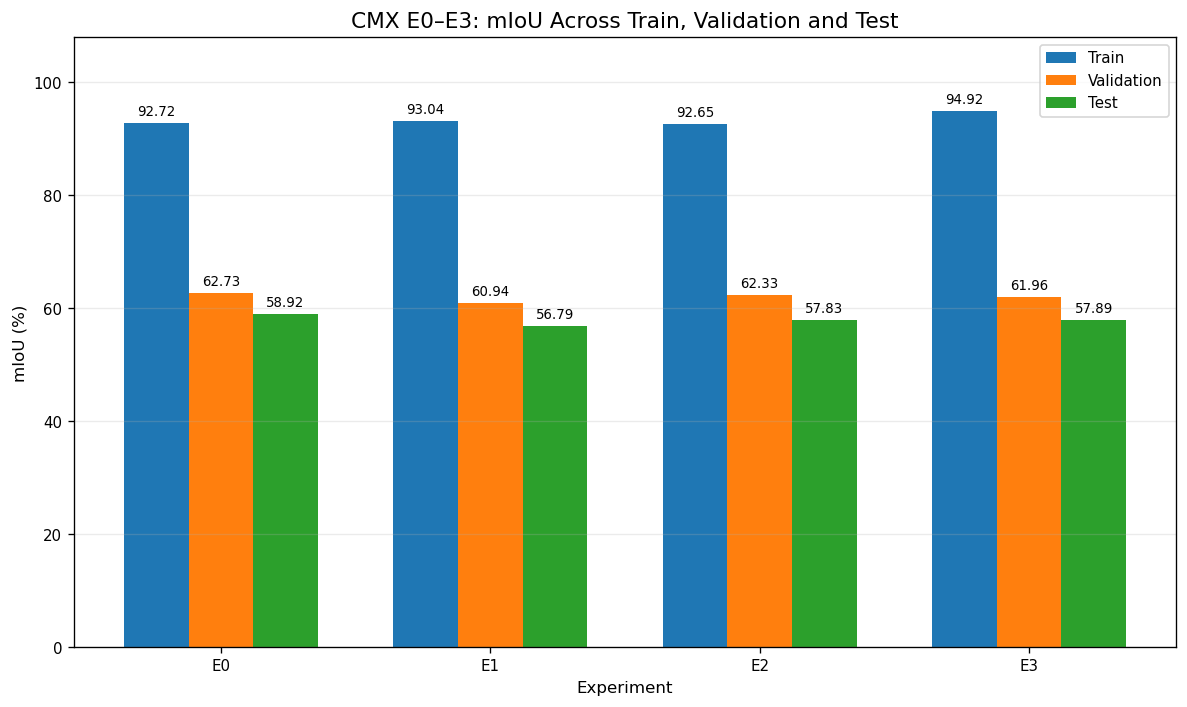

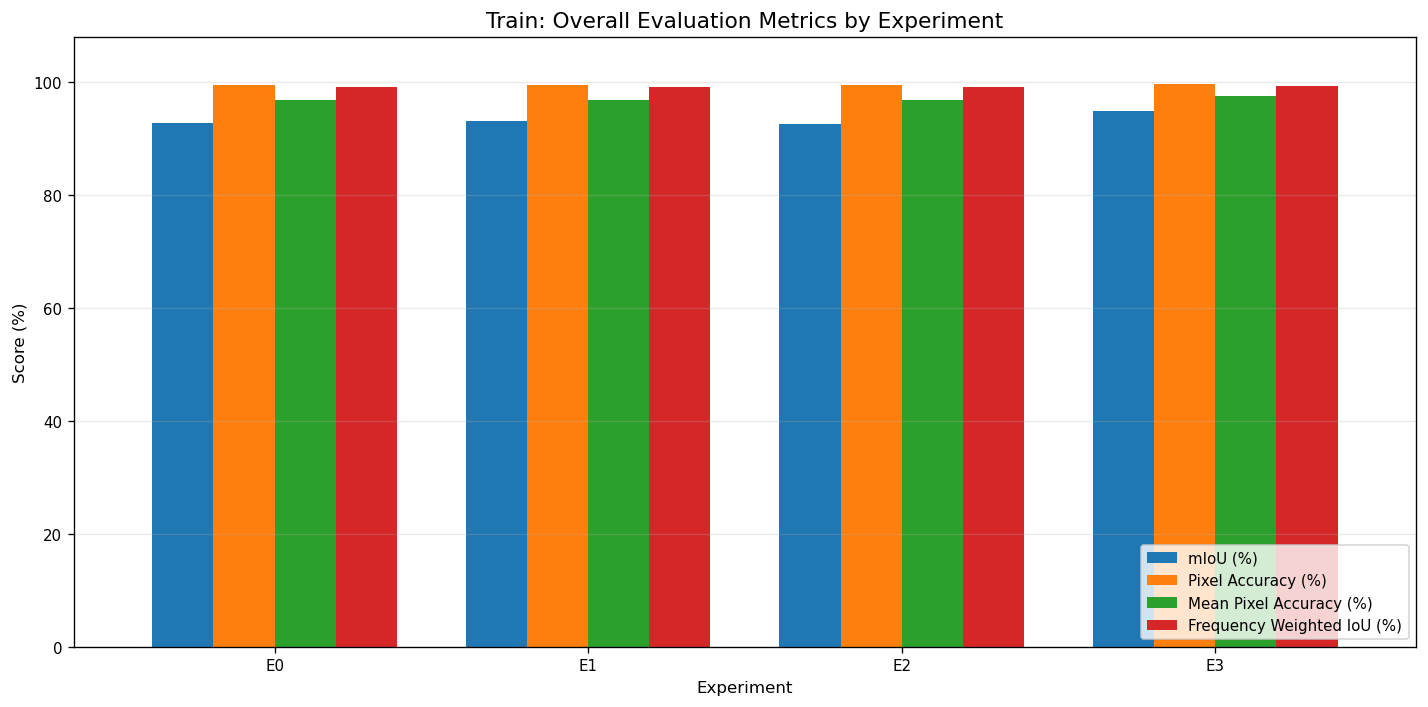

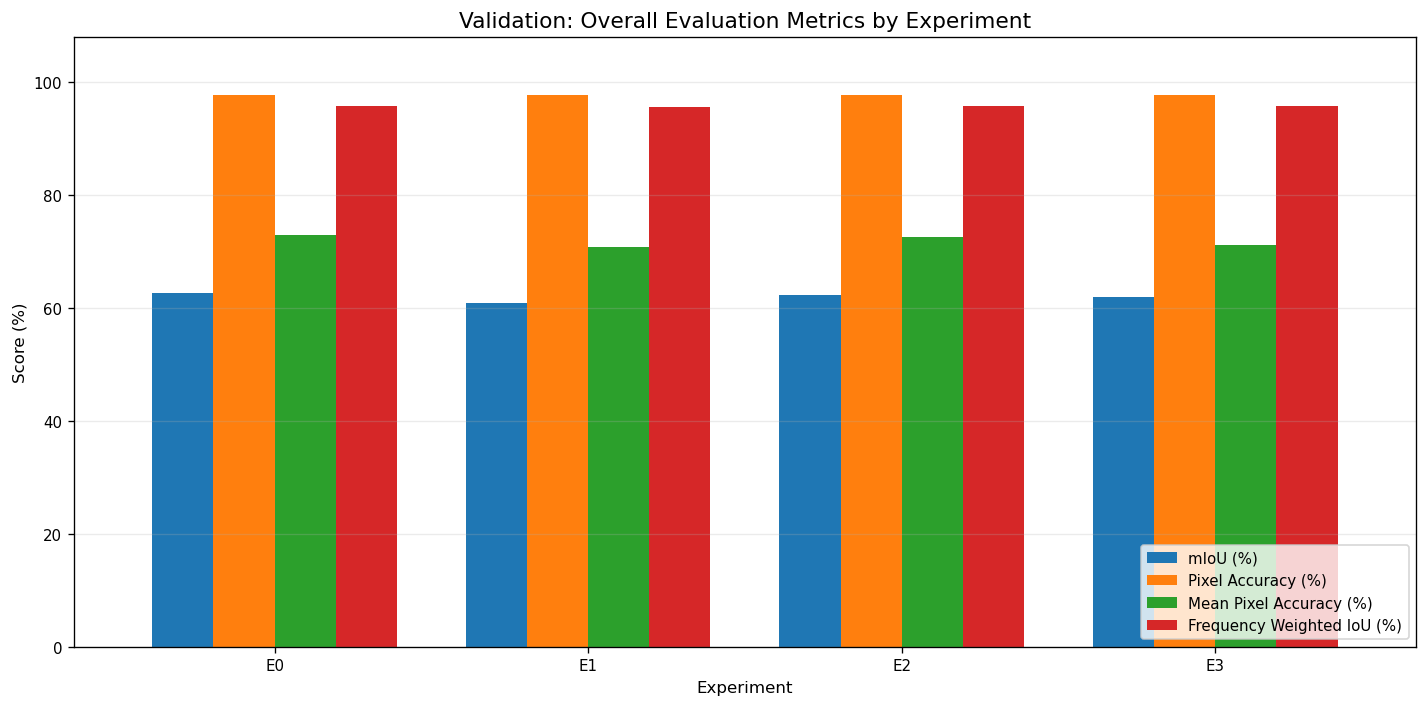

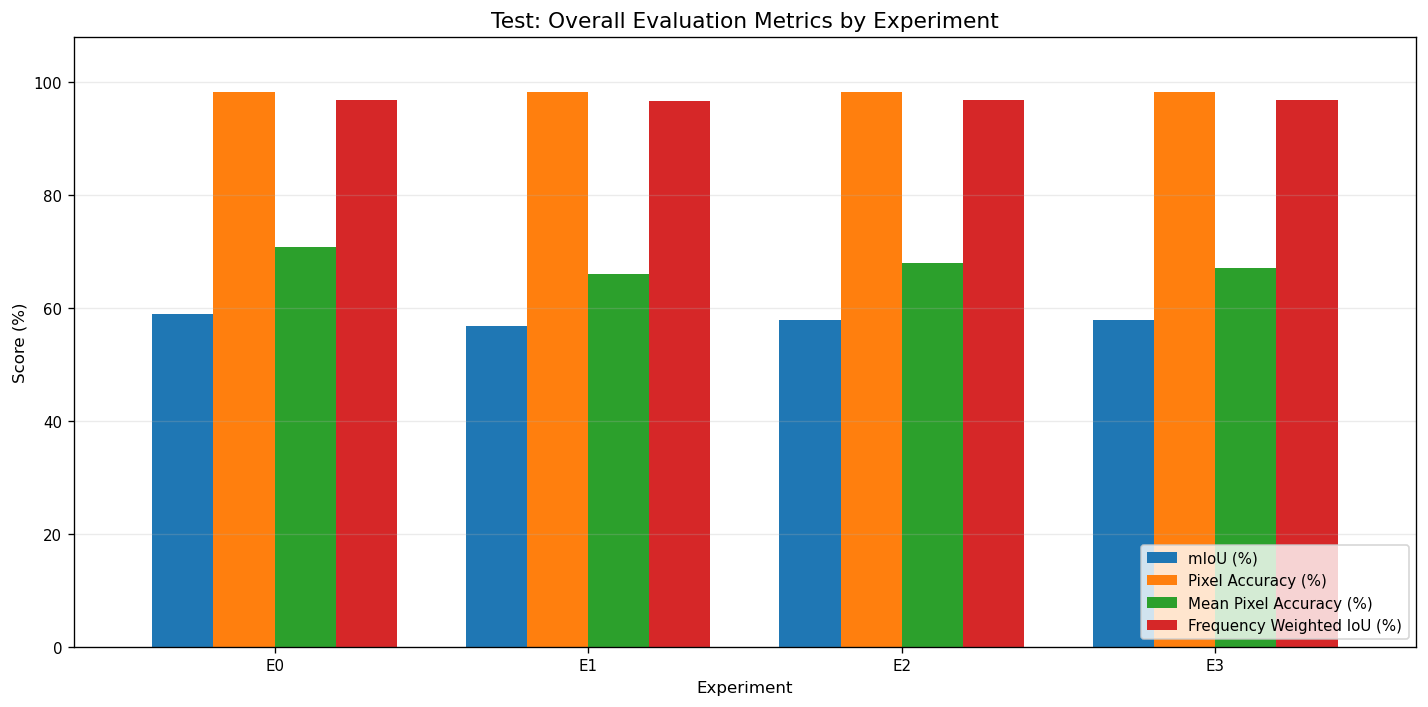

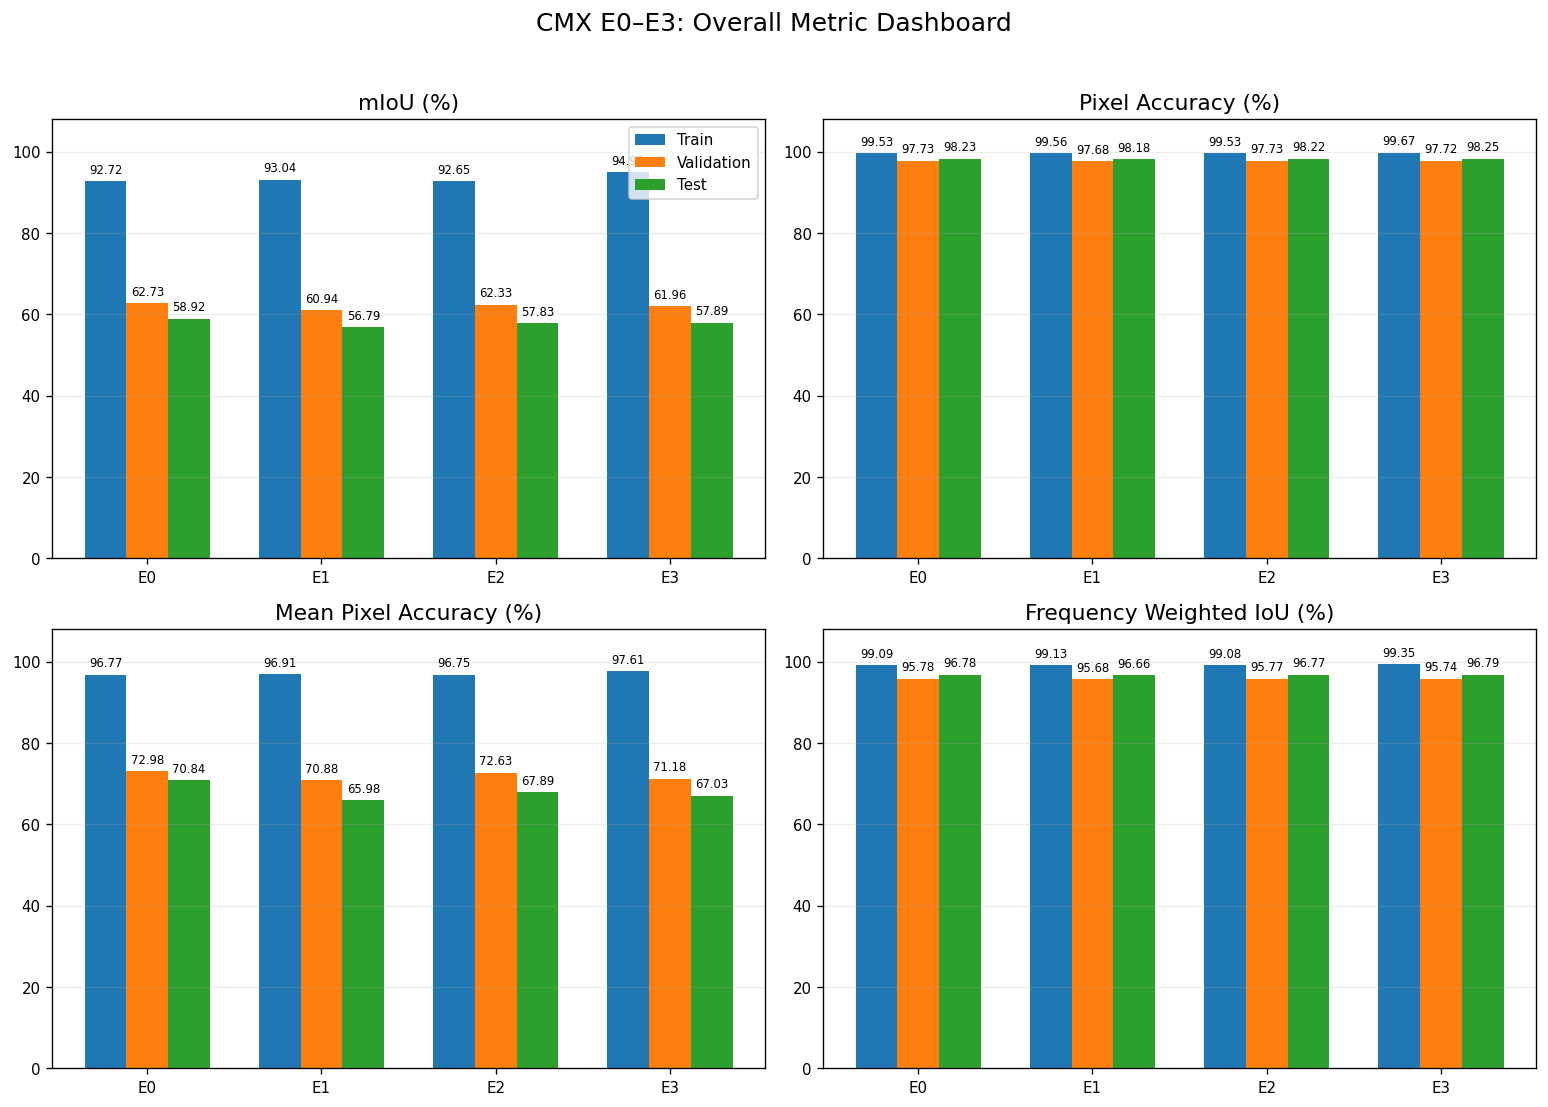

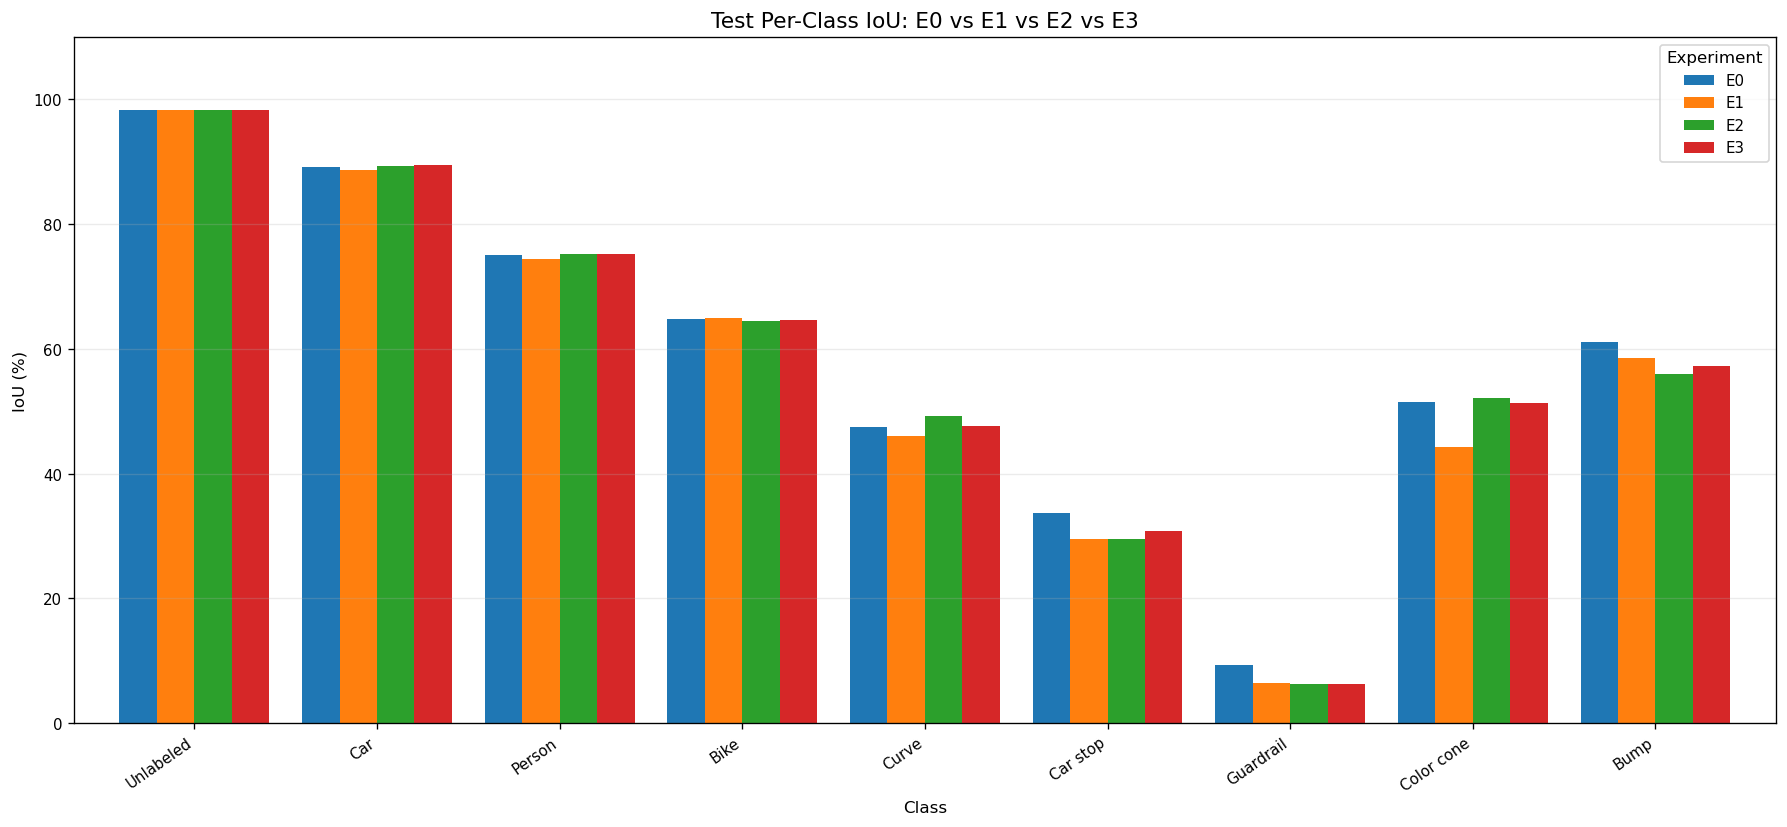

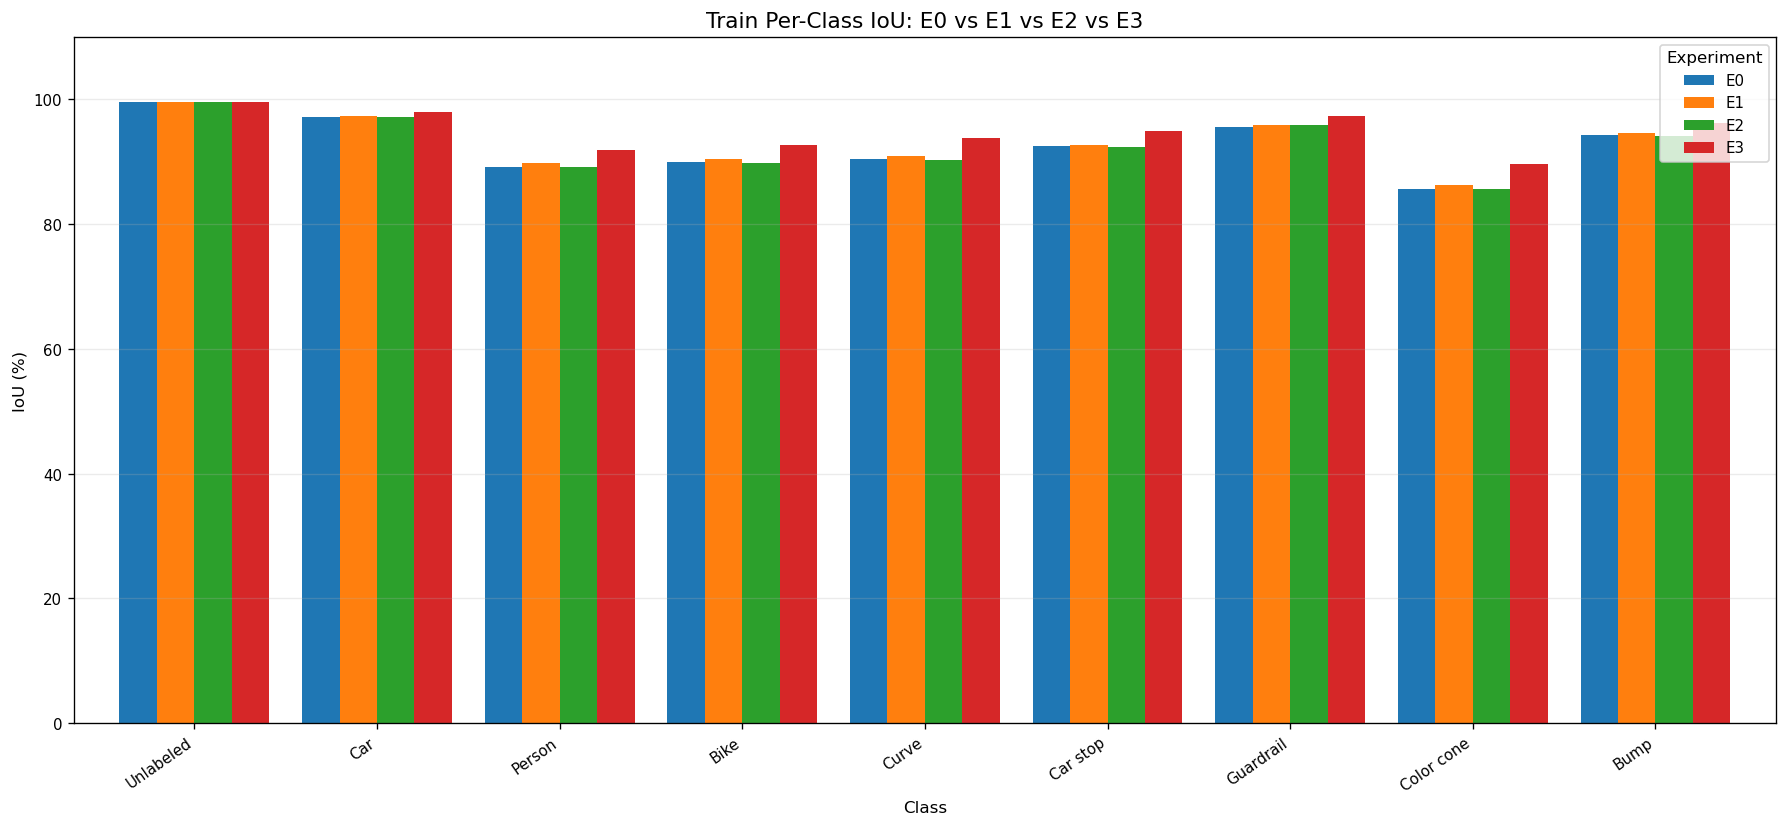

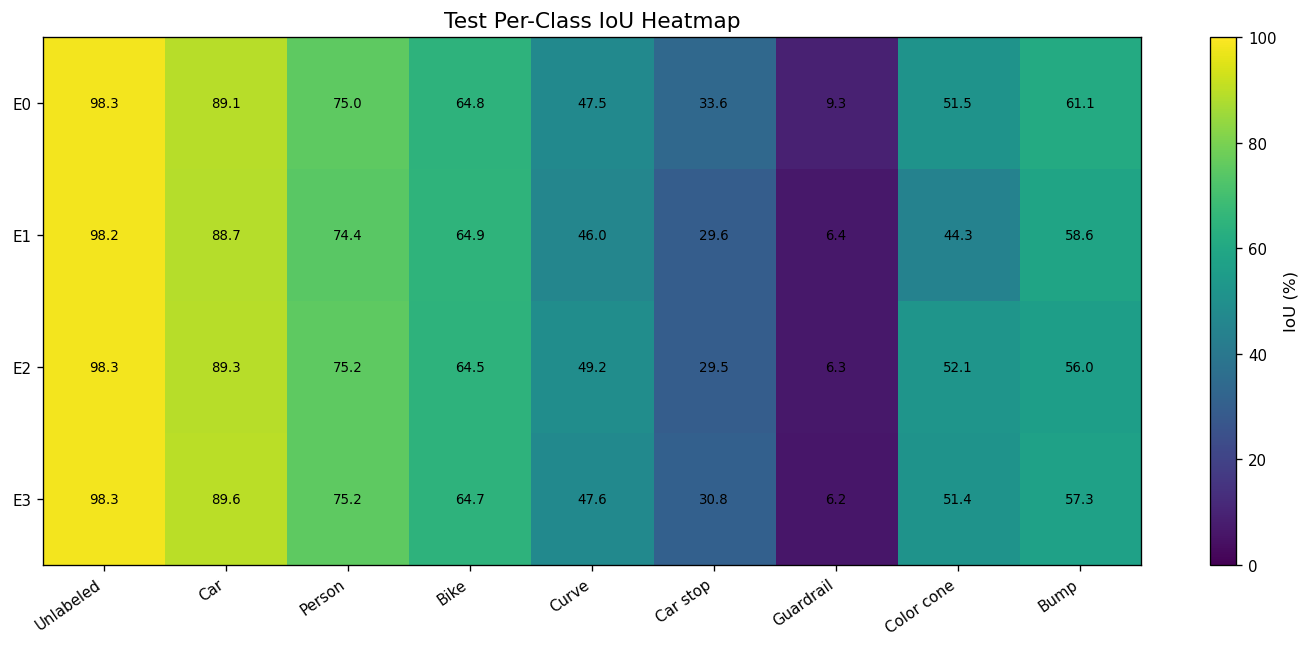

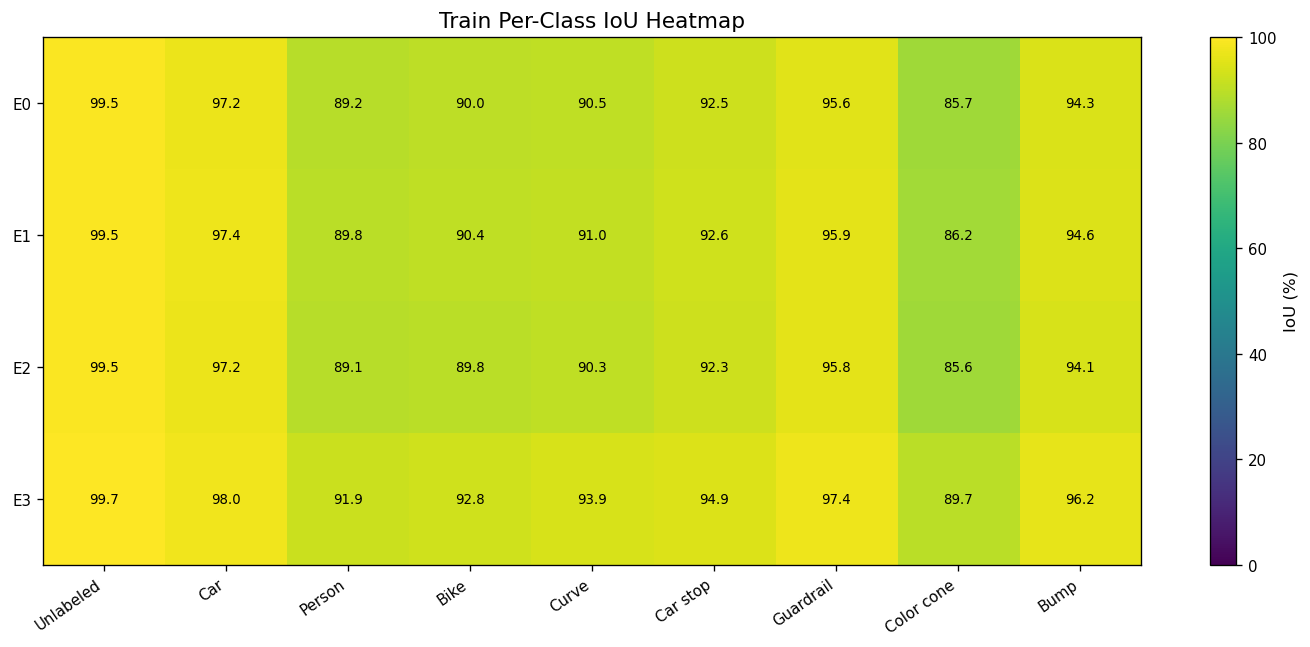

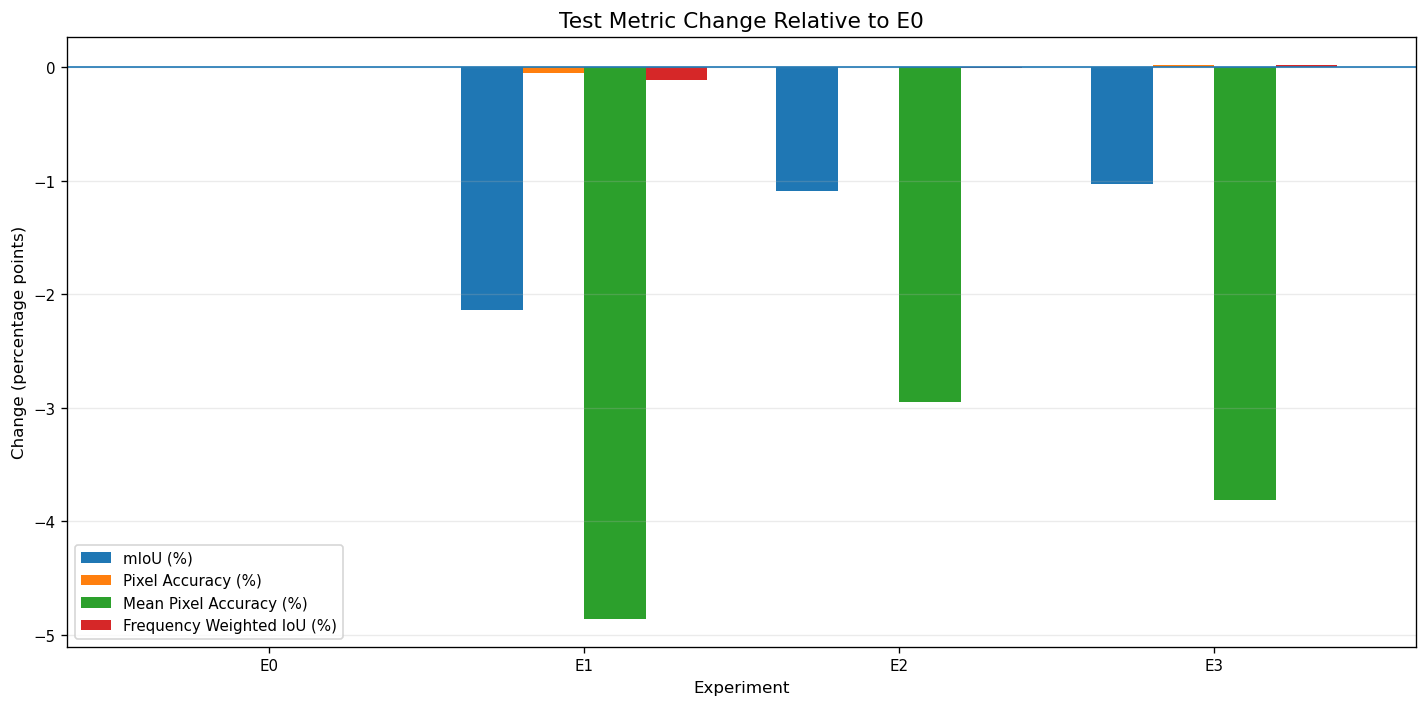

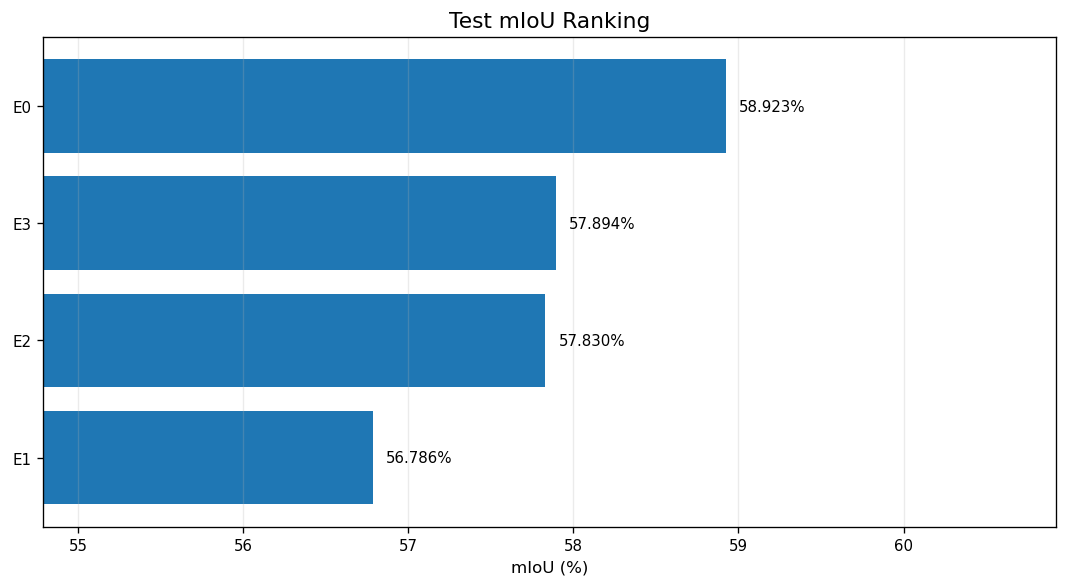

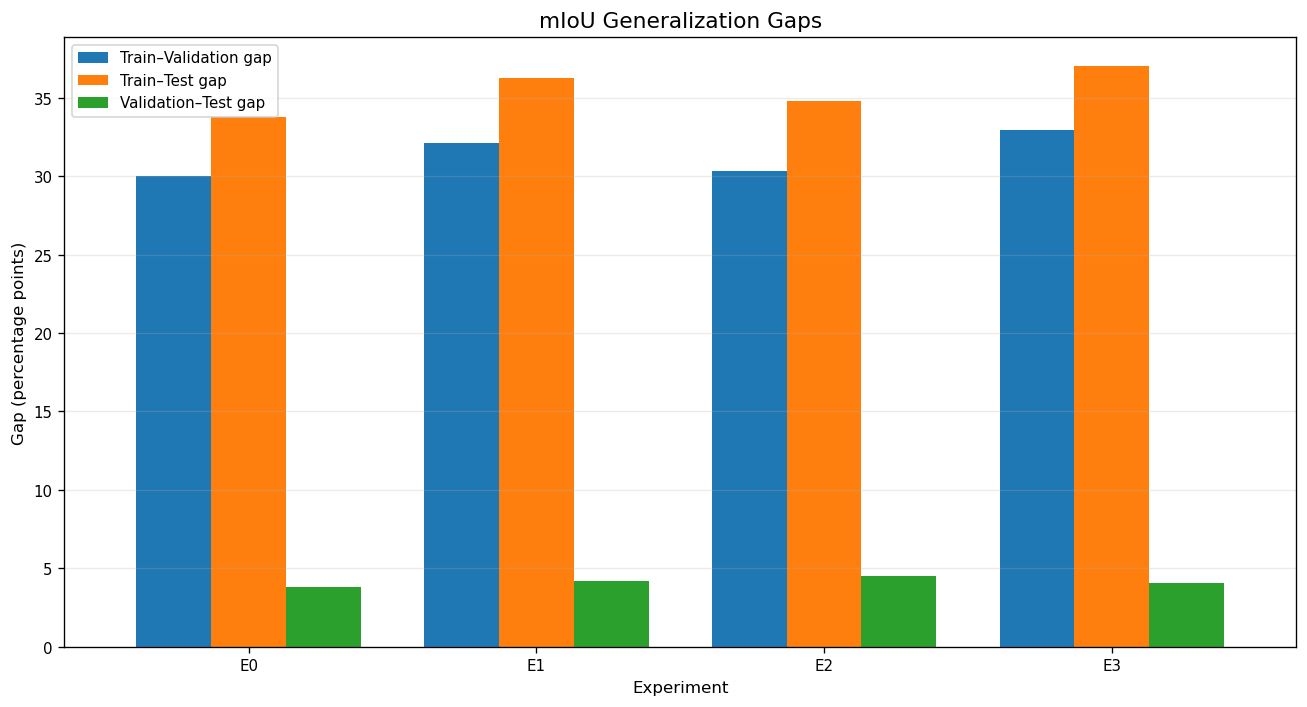

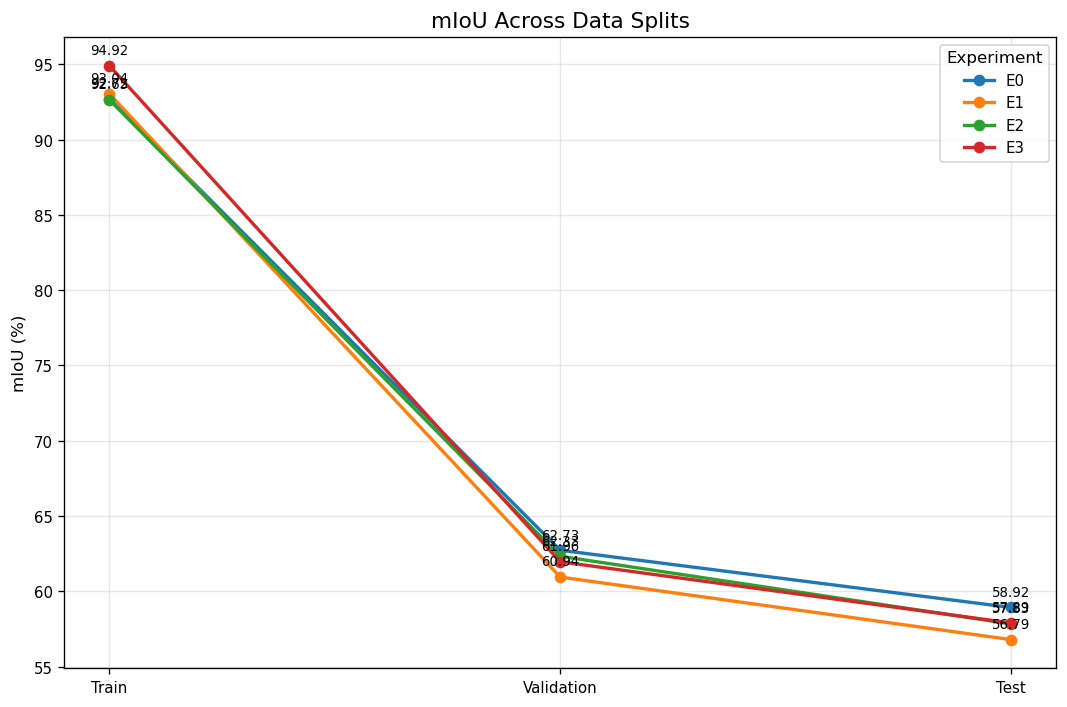

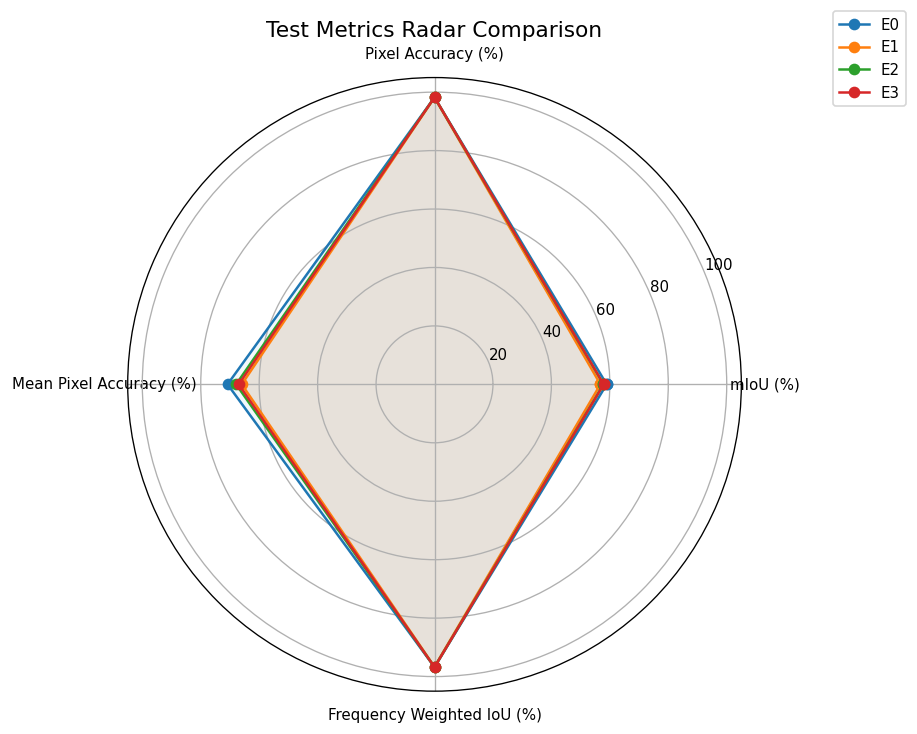

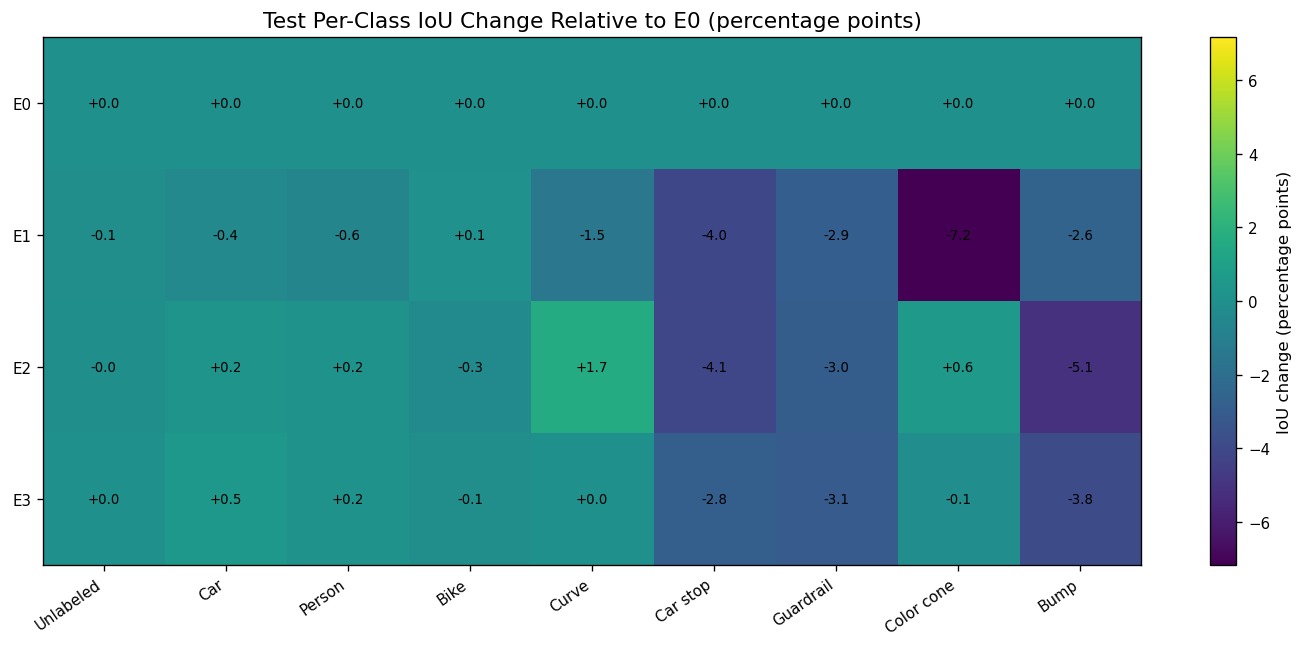


Done! Plots and CSV tables saved to:
/home/cse-sdpl/Downloads/CMX_Research_Plots
PNG plot count: 25

Best recorded validation mIoU: E0 (62.726%)
Best recorded test mIoU: E0 (58.923%)

Important:
- Values are the recorded metrics from the project conversation; cross-check raw logs before publication.
- Validation per-class IoU is not plotted because its exact per-class values are not in the collected results.
- A true confusion matrix cannot be recovered from aggregate metrics alone; it needs pixel-level predictions/labels or confusion counts.


In [1]:
# CMX E0–E3: Complete Research Plotting Notebook
# Uses the recorded metrics; does NOT retrain or modify any model.
# Outputs PNG figures and CSV tables.

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------- Output folder ----------
OUT = Path.home() / "Downloads" / "CMX_Research_Plots"
OUT.mkdir(parents=True, exist_ok=True)

# ---------- Recorded overall metrics (%) ----------
experiments = ["E0", "E1", "E2", "E3"]
splits = ["Train", "Validation", "Test"]
metric_names = [
    "mIoU (%)",
    "Pixel Accuracy (%)",
    "Mean Pixel Accuracy (%)",
    "Frequency Weighted IoU (%)"
]

metrics = {
    "Train": {
        "E0": [92.720, 99.535, 96.772, 99.092],
        "E1": [93.043, 99.557, 96.913, 99.134],
        "E2": [92.646, 99.528, 96.752, 99.080],
        "E3": [94.915, 99.670, 97.607, 99.351],
    },
    "Validation": {
        "E0": [62.726, 97.732, 72.982, 95.784],
        "E1": [60.944, 97.684, 70.880, 95.678],
        "E2": [62.325, 97.731, 72.627, 95.773],
        "E3": [61.961, 97.723, 71.182, 95.739],
    },
    "Test": {
        "E0": [58.923, 98.227, 70.841, 96.777],
        "E1": [56.786, 98.176, 65.979, 96.664],
        "E2": [57.830, 98.224, 67.892, 96.768],
        "E3": [57.894, 98.247, 67.030, 96.792],
    },
}

# ---------- Recorded per-class IoU (%) ----------
classes = [
    "Unlabeled", "Car", "Person", "Bike", "Curve",
    "Car stop", "Guardrail", "Color cone", "Bump"
]

class_iou = {
    "Train": {
        "E0": [99.520, 97.232, 89.233, 90.006, 90.455, 92.457, 95.618, 85.688, 94.267],
        "E1": [99.543, 97.360, 89.765, 90.399, 90.996, 92.626, 95.882, 86.249, 94.563],
        "E2": [99.514, 97.196, 89.110, 89.782, 90.328, 92.313, 95.834, 85.626, 94.115],
        "E3": [99.659, 97.970, 91.854, 92.752, 93.865, 94.882, 97.351, 89.706, 96.198],
    },
    "Test": {
        "E0": [98.303, 89.098, 75.033, 64.802, 47.548, 33.639, 9.273, 51.472, 61.139],
        "E1": [98.237, 88.676, 74.412, 64.871, 46.047, 29.591, 6.372, 44.308, 58.564],
        "E2": [98.296, 89.336, 75.209, 64.498, 49.209, 29.546, 6.311, 52.058, 56.012],
        "E3": [98.314, 89.556, 75.183, 64.706, 47.586, 30.836, 6.209, 51.353, 57.304],
    }
}

# ---------- Style and helper functions ----------
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.titlesize": 13,
    "axes.labelsize": 10,
    "legend.fontsize": 9,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
})

def save_fig(filename):
    plt.tight_layout()
    plt.savefig(OUT / filename, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

def label_bars(ax, bars, fmt="{:.2f}", fontsize=8, rotation=0):
    for bar in bars:
        h = bar.get_height()
        if np.isfinite(h):
            ax.annotate(
                fmt.format(h),
                (bar.get_x() + bar.get_width()/2, h),
                xytext=(0, 3), textcoords="offset points",
                ha="center", va="bottom", fontsize=fontsize,
                rotation=rotation
            )

# ---------- Export core CSV matrices ----------
overall = {}
for split in splits:
    df = pd.DataFrame({e: metrics[split][e] for e in experiments},
                      index=metric_names).T
    df.index.name = "Experiment"
    overall[split] = df
    df.to_csv(OUT / f"overall_metrics_{split.lower()}.csv")

miou_df = pd.DataFrame(
    {split: [metrics[split][e][0] for e in experiments] for split in splits},
    index=experiments
)
miou_df.index.name = "Experiment"
miou_df.to_csv(OUT / "miou_train_validation_test.csv")

class_dfs = {}
for split in ["Train", "Test"]:
    df = pd.DataFrame({e: class_iou[split][e] for e in experiments},
                      index=classes).T
    df.index.name = "Experiment"
    class_dfs[split] = df
    df.to_csv(OUT / f"classwise_iou_{split.lower()}.csv")

# ---------- Plot 1: mIoU across splits ----------
fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(experiments))
width = 0.24
for i, split in enumerate(splits):
    vals = [metrics[split][e][0] for e in experiments]
    bars = ax.bar(x + (i-1)*width, vals, width, label=split)
    label_bars(ax, bars, fontsize=8)
ax.set_title("CMX E0–E3: mIoU Across Train, Validation and Test")
ax.set_xlabel("Experiment")
ax.set_ylabel("mIoU (%)")
ax.set_xticks(x, experiments)
ax.set_ylim(0, 108)
ax.grid(axis="y", alpha=0.25)
ax.legend()
save_fig("01_miou_split_comparison.png")

# ---------- Plots 2–4: all overall metrics, one chart per split ----------
for split in splits:
    df = overall[split]
    ax = df.plot(kind="bar", figsize=(12, 6), width=0.78)
    ax.set_title(f"{split}: Overall Evaluation Metrics by Experiment")
    ax.set_xlabel("Experiment")
    ax.set_ylabel("Score (%)")
    ax.set_ylim(0, 108)
    ax.grid(axis="y", alpha=0.25)
    ax.legend(loc="lower right")
    plt.xticks(rotation=0)
    save_fig(f"0{2 + splits.index(split)}_{split.lower()}_overall_metrics.png")

# ---------- Plot 5: all metrics as small multiples ----------
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for idx, metric in enumerate(metric_names):
    ax = axes.flat[idx]
    xx = np.arange(len(experiments))
    w = 0.24
    for i, split in enumerate(splits):
        vals = [metrics[split][e][idx] for e in experiments]
        bars = ax.bar(xx + (i-1)*w, vals, w, label=split)
        label_bars(ax, bars, fontsize=7)
    ax.set_title(metric)
    ax.set_xticks(xx, experiments)
    ax.set_ylim(0, 108)
    ax.grid(axis="y", alpha=0.22)
    if idx == 0:
        ax.legend()
fig.suptitle("CMX E0–E3: Overall Metric Dashboard", y=1.02, fontsize=15)
save_fig("05_overall_metric_dashboard.png")

# ---------- Plot 6: Test per-class IoU grouped bar chart ----------
test_df = class_dfs["Test"]
ax = test_df.T.plot(kind="bar", figsize=(15, 7), width=0.82)
ax.set_title("Test Per-Class IoU: E0 vs E1 vs E2 vs E3")
ax.set_xlabel("Class")
ax.set_ylabel("IoU (%)")
ax.set_ylim(0, 110)
ax.grid(axis="y", alpha=0.25)
ax.legend(title="Experiment")
plt.xticks(rotation=35, ha="right")
save_fig("06_test_classwise_iou.png")

# ---------- Plot 7: Train per-class IoU grouped bar chart ----------
train_df = class_dfs["Train"]
ax = train_df.T.plot(kind="bar", figsize=(15, 7), width=0.82)
ax.set_title("Train Per-Class IoU: E0 vs E1 vs E2 vs E3")
ax.set_xlabel("Class")
ax.set_ylabel("IoU (%)")
ax.set_ylim(0, 110)
ax.grid(axis="y", alpha=0.25)
ax.legend(title="Experiment")
plt.xticks(rotation=35, ha="right")
save_fig("07_train_classwise_iou.png")

# ---------- Plots 8–9: class-wise heatmaps ----------
for split, df in [("Test", test_df), ("Train", train_df)]:
    fig, ax = plt.subplots(figsize=(12, 5.5))
    values = df[classes].values
    im = ax.imshow(values, aspect="auto", vmin=0, vmax=100)
    ax.set_title(f"{split} Per-Class IoU Heatmap")
    ax.set_xticks(np.arange(len(classes)), classes, rotation=35, ha="right")
    ax.set_yticks(np.arange(len(experiments)), experiments)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            ax.text(j, i, f"{values[i,j]:.1f}", ha="center", va="center", fontsize=8)
    fig.colorbar(im, ax=ax, label="IoU (%)")
    save_fig(f"{8 if split == 'Test' else 9}_{split.lower()}_classwise_heatmap.png")

# ---------- Plot 10: test metric changes relative to E0 ----------
improvement = pd.DataFrame(index=experiments, columns=metric_names, dtype=float)
for e in experiments:
    for j, name in enumerate(metric_names):
        improvement.loc[e, name] = metrics["Test"][e][j] - metrics["Test"]["E0"][j]
improvement.index.name = "Experiment"
improvement.to_csv(OUT / "test_improvement_vs_E0_percentage_points.csv")

ax = improvement.plot(kind="bar", figsize=(12, 6), width=0.78)
ax.axhline(0, linewidth=1)
ax.set_title("Test Metric Change Relative to E0")
ax.set_xlabel("Experiment")
ax.set_ylabel("Change (percentage points)")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=0)
save_fig("10_test_improvement_vs_E0.png")

# ---------- Plot 11: test mIoU ranking ----------
test_miou = pd.Series({e: metrics["Test"][e][0] for e in experiments}).sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(test_miou.index, test_miou.values)
for bar in bars:
    ax.text(bar.get_width() + 0.08, bar.get_y()+bar.get_height()/2,
            f"{bar.get_width():.3f}%", va="center", fontsize=9)
ax.set_title("Test mIoU Ranking")
ax.set_xlabel("mIoU (%)")
ax.set_xlim(max(0, test_miou.min()-2), test_miou.max()+2)
ax.grid(axis="x", alpha=0.25)
save_fig("11_test_miou_ranking.png")

# ---------- Plot 12: generalization gaps ----------
gap_df = pd.DataFrame({
    "Train–Validation gap": [
        metrics["Train"][e][0] - metrics["Validation"][e][0] for e in experiments
    ],
    "Train–Test gap": [
        metrics["Train"][e][0] - metrics["Test"][e][0] for e in experiments
    ],
    "Validation–Test gap": [
        metrics["Validation"][e][0] - metrics["Test"][e][0] for e in experiments
    ],
}, index=experiments)
gap_df.index.name = "Experiment"
gap_df.to_csv(OUT / "miou_generalization_gaps.csv")

ax = gap_df.plot(kind="bar", figsize=(11, 6), width=0.78)
ax.set_title("mIoU Generalization Gaps")
ax.set_xlabel("Experiment")
ax.set_ylabel("Gap (percentage points)")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=0)
save_fig("12_miou_generalization_gaps.png")

# ---------- Plot 13: train/validation/test mIoU line chart ----------
fig, ax = plt.subplots(figsize=(9, 6))
for e in experiments:
    vals = [metrics[s][e][0] for s in splits]
    ax.plot(splits, vals, marker="o", linewidth=2, label=e)
    for split, val in zip(splits, vals):
        ax.annotate(f"{val:.2f}", (split, val), xytext=(0, 7),
                    textcoords="offset points", ha="center", fontsize=8)
ax.set_title("mIoU Across Data Splits")
ax.set_ylabel("mIoU (%)")
ax.grid(alpha=0.3)
ax.legend(title="Experiment")
save_fig("13_miou_split_line_chart.png")

# ---------- Plot 14: test metrics radar chart ----------
radar_metrics = metric_names
angles = np.linspace(0, 2*np.pi, len(radar_metrics), endpoint=False).tolist()
angles += angles[:1]
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, polar=True)
for e in experiments:
    vals = metrics["Test"][e] + metrics["Test"][e][:1]
    ax.plot(angles, vals, marker="o", label=e)
    ax.fill(angles, vals, alpha=0.05)
ax.set_xticks(angles[:-1], radar_metrics)
ax.set_ylim(0, 105)
ax.set_title("Test Metrics Radar Comparison")
ax.legend(loc="upper right", bbox_to_anchor=(1.28, 1.12))
save_fig("14_test_metrics_radar.png")

# ---------- Plot 15: per-class test difference relative to E0 ----------
class_delta = test_df.subtract(test_df.loc["E0"], axis="columns")
class_delta.to_csv(OUT / "test_classwise_iou_change_vs_E0.csv")
fig, ax = plt.subplots(figsize=(12, 5.5))
im = ax.imshow(class_delta.values, aspect="auto",
               vmin=-max(1, np.abs(class_delta.values).max()),
               vmax=max(1, np.abs(class_delta.values).max()))
ax.set_title("Test Per-Class IoU Change Relative to E0 (percentage points)")
ax.set_xticks(np.arange(len(classes)), classes, rotation=35, ha="right")
ax.set_yticks(np.arange(len(experiments)), experiments)
for i in range(class_delta.shape[0]):
    for j in range(class_delta.shape[1]):
        ax.text(j, i, f"{class_delta.iloc[i,j]:+.1f}",
                ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, label="IoU change (percentage points)")
save_fig("15_test_classwise_change_vs_E0.png")

# ---------- Summary ----------
print(f"\nDone! Plots and CSV tables saved to:\n{OUT}")
print(f"PNG plot count: {len(list(OUT.glob('*.png')))}")
print("\nBest recorded validation mIoU:", miou_df["Validation"].idxmax(),
      f"({miou_df['Validation'].max():.3f}%)")
print("Best recorded test mIoU:", miou_df["Test"].idxmax(),
      f"({miou_df['Test'].max():.3f}%)")
print("\nImportant:")
print("- Values are the recorded metrics from the project conversation; cross-check raw logs before publication.")
print("- Validation per-class IoU is not plotted because its exact per-class values are not in the collected results.")
print("- A true confusion matrix cannot be recovered from aggregate metrics alone; it needs pixel-level predictions/labels or confusion counts.")
